# Proyecto #3 — Bitácora de Zafra: casos de uso de LLM

**CC3092 · Deep Learning y Sistemas Inteligentes** — Universidad del Valle de Guatemala
**Nicolás Concuá (23197) y Esteban Cárcamo (23016)** · noviembre de 2026

Enlace al repositorio: https://github.com/nicoCT04/Proyecto3-LLMS

Este notebook **no es el producto** (el producto es la aplicación web en `backend/` + `frontend/`). Aquí se
documenta el análisis de los datos, el pipeline y la evaluación objetiva de cada iteración, leyendo los
resultados guardados por `eval/evaluar.py` (las respuestas del LLM están en caché, por lo que todo es reproducible
sin volver a llamar a la API).

## 1. Problema y usuario objetivo

Durante la zafra, los caporales y supervisores de campo de un ingenio reportan su jornada con **notas informales**
(WhatsApp, audios): lote, toneladas cortadas, hora de la quema, caña que quedó sin despachar, paros de maquinaria e
incidentes. Alguien en oficina debe transcribirlas a mano y, mientras tanto, nadie detecta a tiempo la **caña quemada
que espera** (pierde sacarosa cada hora) ni los paros largos.

**Bitácora de Zafra** convierte cada nota en un registro estructurado con un LLM y aplica reglas del ingenio para
generar alertas (azúcar en riesgo, paros, accidentes, plagas). El éxito se mide como:

* **Calidad de extracción**: precision, recall y F1 por campo (micro), y % de notas 100 % correctas.
* **Calidad de las alertas**: F1 entre las alertas derivadas de la predicción y las de la referencia.
* **Seguridad**: tasa de alucinación (valores inventados) y resistencia a *prompt injection* / mensajes fuera de tema.
* **Operación**: latencia, tokens y costo por reporte.

In [1]:
import json, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)

RAIZ = Path.cwd() if (Path.cwd() / "backend").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ / "backend")); sys.path.insert(0, str(RAIZ / "eval"))
from zafra import reglas, catalogo
from zafra.extractor import ITERACIONES, FINAL
from metricas import resumir, conteos_caso, CAMPOS

REPORTS = RAIZ / "reports"; REPORTS.mkdir(exist_ok=True)
RES = RAIZ / "eval" / "resultados"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10})
VERDE, AMBAR, AZUL, GRIS = "#2e7d5b", "#c9821f", "#3f6fb0", "#9aa59f"

casos = [json.loads(l) for l in open(RAIZ / "data" / "eval_set.jsonl", encoding="utf-8")]
banco = [json.loads(l) for l in open(RAIZ / "data" / "fewshot_pool.jsonl", encoding="utf-8")]
print(f"{len(casos)} casos de evaluación · {len(banco)} ejemplos few-shot · {len(catalogo.lotes())} lotes")

60 casos de evaluación · 16 ejemplos few-shot · 48 lotes


## 2. Datos

**Fuentes.** (1) Catálogo de 48 lotes de 16 fincas (variedad, hectáreas, pol, brix), derivado de la base SQLite
del servidor *sugarmill* del proyecto de Redes; (2) notas de campo escritas a mano imitando WhatsApp y audios
transcritos; (3) la entrada del usuario en la aplicación.

**Conjunto de evaluación propio.** 60 notas con su respuesta de referencia anotada según `data/GUIA_ANOTACION.md`
(validada por ambos integrantes en `data/validacion_humana.md`), divididas en *dev* (20, para ajustar prompts) y
*test* (40, solo para reportar). Incluye notas normales, difíciles (números en letras, horas coloquiales,
ambigüedad de lote, cuadrillas, unidades mixtas) y adversariales (prompt injection y fuera de tema). Un banco
separado de 16 notas se usa como ejemplos few-shot (nunca se evalúa sobre él).

split,dev,test,All
categoria,,,
adversarial,4,4,8
dificil,4,8,12
normal,12,28,40
All,20,40,60


Largo de las notas (caracteres): {'mean': 96.4, 'min': 2.0, '50%': 99.5, 'max': 181.0}


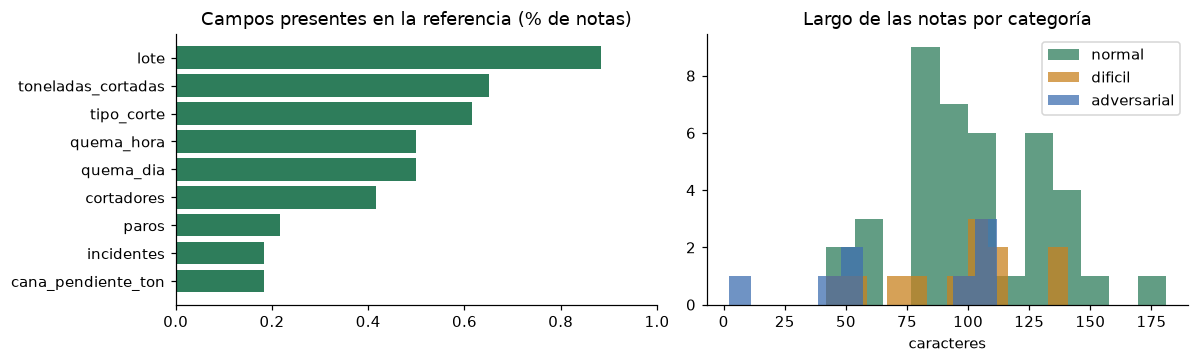

In [2]:
df = pd.DataFrame([{**{k: c[k] for k in ("id", "split", "categoria", "reportado")},
                    "caracteres": len(c["texto"]), "palabras": len(c["texto"].split()),
                    **{f"tiene_{k}": c["gold"][k] is not None for k in CAMPOS},
                    "tiene_paros": bool(c["gold"]["paros"]), "tiene_incidentes": bool(c["gold"]["incidentes"]),
                    "fuera_de_tema": c["gold"]["fuera_de_tema"]} for c in casos])
display(pd.crosstab(df.categoria, df.split, margins=True))
print("Largo de las notas (caracteres):", df.caracteres.describe()[["mean", "min", "50%", "max"]].round(1).to_dict())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
cobertura = df[[c for c in df.columns if c.startswith("tiene_")]].mean().sort_values()
ax[0].barh([c.replace("tiene_", "") for c in cobertura.index], cobertura.values, color=VERDE)
ax[0].set_title("Campos presentes en la referencia (% de notas)"); ax[0].set_xlim(0, 1)
for cat, col in zip(["normal", "dificil", "adversarial"], [VERDE, AMBAR, AZUL]):
    ax[1].hist(df[df.categoria == cat].caracteres, bins=12, alpha=0.75, label=cat, color=col)
ax[1].set_title("Largo de las notas por categoría"); ax[1].set_xlabel("caracteres"); ax[1].legend()
plt.tight_layout(); plt.savefig(REPORTS / "datos_eval_set.png", bbox_inches="tight"); plt.show()

## 3. Pipeline del sistema

```
nota (texto / audio) ─► transcripción (Gemini, multimodal) ─► preprocesamiento (NFC, sin caracteres de
control, ≤1500 caracteres, delimitadores <nota> neutralizados) ─► embedding de la nota (gemini-embedding-001,
768 d) ─► similitud coseno contra el banco (top-4) ─► prompt = reglas + catálogo + 4 ejemplos + nota ─►
LLM con salida JSON y esquema estricto ─► validación (Pydantic, catálogo de lotes, rangos, autocorrección)
─► reglas del ingenio (horas desde la quema, KATC, azúcar en riesgo, alertas) ─► confirmación humana
─► SQLite ─► tablero (KPIs, alertas, CSV)
```

Decisión clave: **el LLM solo extrae hechos; toda la aritmética es determinista** (conversión de jaulas y viajes
a toneladas, horas desde la quema, pérdida de azúcar). Así un error de cálculo del modelo no puede llegar al
tablero, y las alertas se pueden recalcular cuando el supervisor corrige un campo.

In [3]:
def cargar(it):
    ruta = RES / f"{it}.jsonl"
    return [json.loads(l) for l in open(ruta, encoding="utf-8")] if ruta.exists() else None

resultados = {it: cargar(it) for it in ITERACIONES}
resultados = {k: v for k, v in resultados.items() if v}
print("Iteraciones con resultados:", list(resultados))

tok = pd.DataFrame([{"iteracion": it, "entrada": f["salida"]["traza"]["tokens_entrada"],
                     "salida": f["salida"]["traza"]["tokens_salida"],
                     "razonamiento": f["salida"]["traza"]["tokens_razonamiento"]}
                    for it, filas in resultados.items() for f in filas
                    if f["salida"]["traza"]["modelo"] != "regex" and "error" not in f["salida"]["traza"]])
display(tok.groupby("iteracion").agg(["mean", "max"]).round(0))

Iteraciones con resultados: ['It0', 'It1', 'It2', 'It3', 'It4', 'It5', 'It6', 'It7', 'It8']


entrada       salida      razonamiento      
             mean   max   mean  max         mean   max
iteracion                                             
It1         171.0   190  148.0  208          0.0     0
It2        1169.0  1188  153.0  248          0.0     0
It3        1859.0  1878  130.0  225          0.0     0
It4        1927.0  1983  125.0  239          0.0     0
It5        1927.0  1983  125.0  239          0.0     0
It6        2019.0  2075  125.0  177          0.0     0
It7        2203.0  4299  133.0  182       1183.0  4090
It8        2019.0  2067  138.0  213          0.0     0

Medido en la tabla anterior: el prompt simple (It1) usa ~170 tokens de entrada, por lo que la nota
ocupa del orden de 60–80 tokens; el prompt detallado con reglas y catálogo (It2) sube a ~1 170, y los cuatro
ejemplos recuperados agregan ~850 más (It6: ~2 020). La salida es de ~125 tokens. En total, una solicitud usa
alrededor del 0.2 % de la ventana de contexto de 1 M tokens de Gemini Flash-Lite, así que el contexto no es una
restricción; lo que se controla es el **costo y la latencia**, con el límite de 1 500 caracteres por nota,
`top-k = 4` y `max_output_tokens = 2048`. Gemma (It7) además gasta ~1 200 tokens de razonamiento interno.

## 4. Recuperación de ejemplos (few-shot dinámico)

Cada nota se convierte en un embedding de 768 dimensiones (`gemini-embedding-001` con truncado Matryoshka) y se
compara con las 16 notas del banco por **similitud coseno**; las 4 más parecidas entran al prompt como ejemplos.
La idea es la misma que en RAG: en lugar de recuperar documentos, se recuperan *demostraciones* de la tarea.

,top1,top4
categoria,,
adversarial,0.796,0.769
dificil,0.875,0.848
normal,0.886,0.850


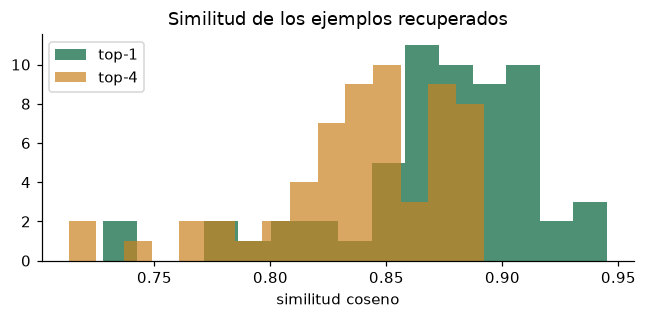

Nota: en el catorce sacamos como trescientas toneladitas con cuarenta y dos cortadores, la quema fue como a las cuatro y media de la madrugada
  0.906  Finca Santa Ana, cortamos bastante hoy como 300 toneladas, quemamos a las 5am
  0.883  Buenas ing. Reporte lote 5: cortamos 310 toneladas con 42 cortadores, la quema fue hoy a las 4:
  0.883  Lote 30: cortadores 55, toneladas 380. quema hoy 3:15am. sin novedad
  0.878  reporte: lote 41, 38 cortadores, cortaron 270 t. Se quemo ayer como a las 5 y media de la tarde


In [4]:
it_dyn = "It4" if "It4" in resultados else None
if it_dyn:
    sims = pd.DataFrame([{"id": f["caso"]["id"], "categoria": f["caso"]["categoria"],
                          **{f"top{i+1}": e["similitud"] for i, e in enumerate(f["salida"]["traza"]["ejemplos"])}}
                         for f in resultados[it_dyn]])
    display(sims.groupby("categoria")[["top1", "top4"]].mean().round(3))
    fig, ax = plt.subplots(figsize=(6, 3))
    ax.hist(sims.top1, bins=15, color=VERDE, alpha=.85, label="top-1")
    ax.hist(sims.top4, bins=15, color=AMBAR, alpha=.7, label="top-4")
    ax.set_xlabel("similitud coseno"); ax.set_title("Similitud de los ejemplos recuperados"); ax.legend()
    plt.tight_layout(); plt.savefig(REPORTS / "similitud_recuperacion.png", bbox_inches="tight"); plt.show()
    ej = next(f for f in resultados[it_dyn] if f["caso"]["id"] == "E041")
    print("Nota:", ej["caso"]["texto"])
    for e in ej["salida"]["traza"]["ejemplos"]:
        print(f"  {e['similitud']:.3f}  {e['texto'][:95]}")

## 5. Resultados por iteración

Cada iteración cambia **una cosa** respecto a la anterior (registro completo en `eval/resultados/registro.csv`,
con el hash del prompt y los parámetros de generación: `temperature = 0`, `top_p = 0.95`,
`max_output_tokens = 2048`, razonamiento interno `low`). Las métricas que se reportan son las del split **test**.

In [5]:
filas = []
for it, res in resultados.items():
    for sp in ("dev", "test"):
        sub = [f for f in res if f["caso"]["split"] == sp]
        if not sub:
            continue
        filas.append({"iteracion": it, "split": sp, "cambio": ITERACIONES[it].descripcion, "n": len(sub),
                      **resumir(sub)})
tabla = pd.DataFrame(filas)
cols = ["iteracion", "cambio", "n", "precision", "recall", "f1", "exactitud_nota", "f1_alertas",
        "tasa_alucinacion", "f1_fuera_de_tema", "json_valido", "latencia_media_s", "costo_usd_por_1000"]
test = tabla[tabla.split == "test"][cols].set_index("iteracion")
test.to_csv(REPORTS / "tabla_iteraciones_test.csv")
display(test.round(3))

,cambio,n,precision,recall,f1,exactitud_nota,f1_alertas,tasa_alucinacion,f1_fuera_de_tema,json_valido,latencia_media_s,costo_usd_por_1000
iteracion,,,,,,,,,,,,
It0,Baseline sin LLM: expresiones regulares y pala...,40,0.914,0.749,0.823,0.325,0.774,0.050,0.4,1.000,0.000,0.000
It1,"Prompt simple, modo JSON sin esquema (zero-shot)",40,0.917,0.643,0.756,0.175,0.813,0.083,0.8,1.000,0.981,0.077
It2,Prompt detallado (reglas + catálogo + segurida...,40,0.971,0.971,0.971,0.775,1.000,0.023,1.0,1.000,1.107,0.179
It3,It2 + 4 ejemplos few-shot fijos,40,0.976,0.959,0.968,0.800,1.000,0.018,0.8,1.000,1.129,0.237
It4,It2 + 4 ejemplos few-shot elegidos por embeddi...,40,0.976,0.965,0.971,0.850,0.973,0.018,0.8,1.000,1.320,0.243
It5,It4 + validación contra catálogo y autocorrecc...,40,0.976,0.965,0.971,0.850,0.973,0.018,0.8,1.000,1.320,0.243
It6,It5 + prompt v3: aclaraciones de lote numérico...,40,0.982,0.965,0.973,0.850,0.973,0.012,0.8,1.000,1.140,0.252
It7,Configuración de It6 con un modelo abierto (Ge...,40,0.994,0.942,0.967,0.850,0.973,0.006,1.0,0.925,30.959,0.000
It8,Configuración de It6 con el modelo grande (gem...,18,1.000,0.958,0.979,0.944,1.000,0.000,1.0,1.000,1.641,0.951


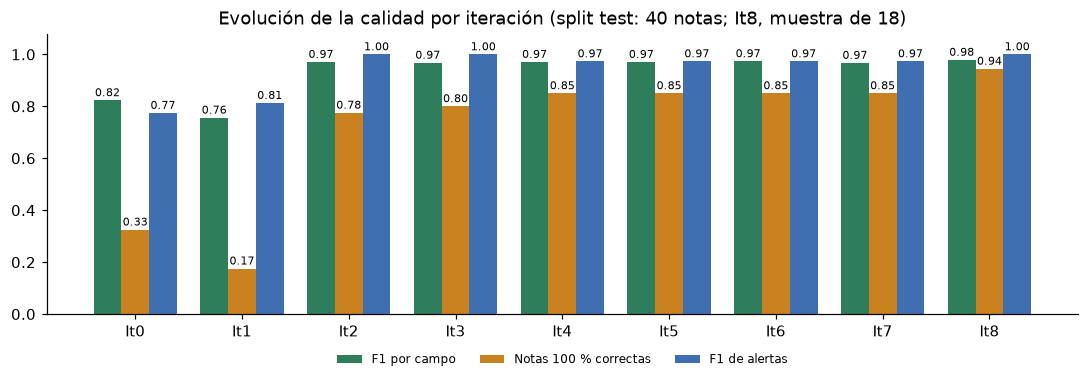

In [6]:
fig, ax = plt.subplots(figsize=(10, 3.6))
x = np.arange(len(test)); w = 0.26
for i, (k, n, c) in enumerate([("f1", "F1 por campo", VERDE), ("exactitud_nota", "Notas 100 % correctas", AMBAR),
                               ("f1_alertas", "F1 de alertas", AZUL)]):
    b = ax.bar(x + (i - 1) * w, test[k], w, label=n, color=c)
    ax.bar_label(b, fmt="%.2f", fontsize=7, padding=1)
ax.set_xticks(x, test.index); ax.set_ylim(0, 1.08)
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1), fontsize=8, frameon=False)
ax.set_title("Evolución de la calidad por iteración (split test: 40 notas; It8, muestra de 18)")
plt.tight_layout(); plt.savefig(REPORTS / "metricas_iteraciones.png", bbox_inches="tight"); plt.show()

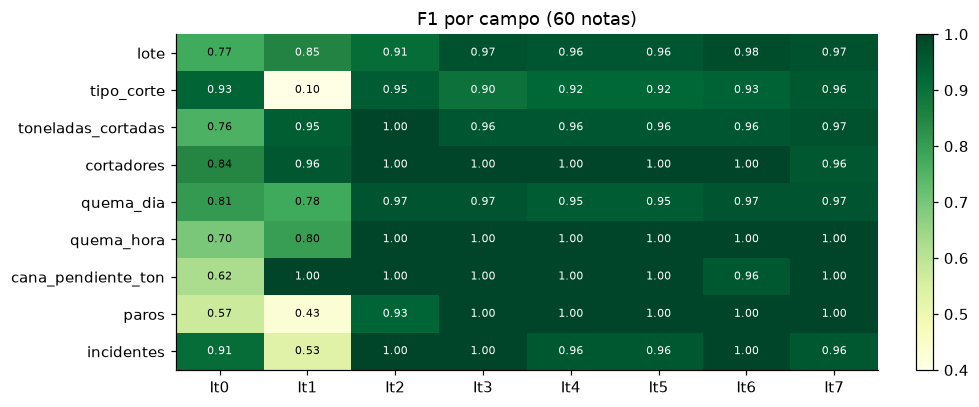

,It0,It1,It2,It3,It4,It5,It6,It7
normal,0.35,0.18,0.72,0.88,0.88,0.88,0.90,0.98
dificil,0.08,0.17,0.75,0.58,0.58,0.58,0.75,0.58
adversarial,0.62,0.62,1.00,0.75,0.88,0.88,0.75,0.88


In [7]:
# F1 por campo e iteración (todas las notas)
campos = CAMPOS + ["paros", "incidentes"]
mapa = pd.DataFrame({it: {c: resumir(res)[f"f1_{c}"] for c in campos}
                     for it, res in resultados.items() if it != "It8"})
fig, ax = plt.subplots(figsize=(9, 3.8))
im = ax.imshow(mapa.values, cmap="YlGn", vmin=0.4, vmax=1, aspect="auto")
ax.set_xticks(range(mapa.shape[1]), mapa.columns); ax.set_yticks(range(mapa.shape[0]), mapa.index)
for i in range(mapa.shape[0]):
    for j in range(mapa.shape[1]):
        v = mapa.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if v > 0.85 else "black")
ax.set_title("F1 por campo (60 notas)"); plt.colorbar(im, ax=ax, fraction=0.03)
plt.tight_layout(); plt.savefig(REPORTS / "f1_por_campo.png", bbox_inches="tight"); plt.show()

cat = pd.DataFrame({it: {c: np.mean([conteos_caso(f["salida"]["reporte"], f["caso"]["gold"])["exacto"]
                                     for f in res if f["caso"]["categoria"] == c])
                         for c in ("normal", "dificil", "adversarial")}
                    for it, res in resultados.items() if it != "It8"})
display(cat.round(2))

### Comparación de modelos sobre la misma muestra

El tier gratuito de la API limita `gemini-3.5-flash` a 20 solicitudes por día, por lo que el modelo grande (It8)
se evaluó sobre una muestra de 18 notas espaciadas uniformemente. Para comparar de forma justa, los tres modelos
se miden sobre **esas mismas notas** con la configuración final.

In [8]:
if "It8" in resultados:
    ids = {f["caso"]["id"] for f in resultados["It8"]}
    comp = []
    for it in ("It0", FINAL, "It7", "It8"):
        if it in resultados:
            sub = [f for f in resultados[it] if f["caso"]["id"] in ids]
            r = resumir(sub)
            comp.append({"iteracion": it, "modelo": sub[0]["salida"]["traza"]["modelo"], "n": len(sub),
                         **{k: r[k] for k in ("f1", "exactitud_nota", "f1_alertas", "tasa_alucinacion",
                                               "latencia_media_s", "costo_usd_por_1000")}})
    comp = pd.DataFrame(comp).set_index("iteracion")
    comp.to_csv(REPORTS / "comparacion_modelos_muestra.csv")
    display(comp.round(3))
else:
    print("It8 (modelo grande) aún no se ha corrido.")

,modelo,n,f1,exactitud_nota,f1_alertas,tasa_alucinacion,latencia_media_s,costo_usd_por_1000
iteracion,,,,,,,,
It0,regex,18,0.851,0.389,0.571,0.081,0.000,0.000
It6,gemini-3.5-flash-lite,18,0.979,0.833,0.889,0.027,1.094,0.249
It7,gemma-4-26b-a4b-it,18,0.986,0.889,1.000,0.000,26.035,0.000
It8,gemini-3.5-flash,18,0.979,0.944,1.000,0.000,1.641,0.951


## 6. Métricas operativas

Latencia medida de la llamada al modelo (sin caché), tokens por solicitud y costo estimado con los precios de
referencia de `backend/zafra/config.py` (verificar contra la página oficial antes de citarlos).

,latencia_media_s,costo_usd_por_1000,latencia_p95_s,tokens_entrada,tokens_salida
iteracion,,,,,
It0,0.000,0.000,0.000,0.000,0.000
It1,0.981,0.077,1.274,170.950,148.875
It2,1.107,0.179,1.324,1168.950,155.825
It3,1.129,0.237,1.507,1858.950,128.500
It4,1.320,0.243,2.616,1929.925,125.900
It5,1.320,0.243,2.616,1929.925,125.900
It6,1.140,0.252,1.332,2021.925,124.125
It7,30.959,0.000,85.421,2258.975,133.525
It8,1.641,0.951,2.548,2018.944,138.222


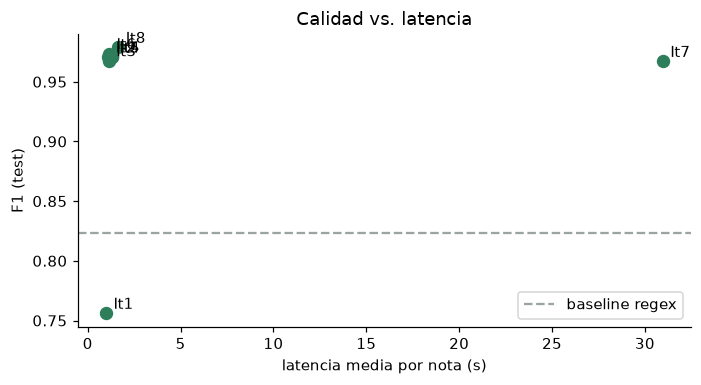

In [9]:
op = test[["latencia_media_s", "costo_usd_por_1000"]].copy()
op["latencia_p95_s"] = tabla[tabla.split == "test"].set_index("iteracion")["latencia_p95_s"]
op["tokens_entrada"] = tabla[tabla.split == "test"].set_index("iteracion")["tokens_entrada_medios"]
op["tokens_salida"] = tabla[tabla.split == "test"].set_index("iteracion")["tokens_salida_medios"]
display(op.round(3))
fig, ax = plt.subplots(figsize=(6.5, 3.6))
llm_its = [i for i in op.index if i != "It0"]
ax.scatter(op.loc[llm_its, "latencia_media_s"], test.loc[llm_its, "f1"], s=60, color=VERDE)
for i in llm_its:
    ax.annotate(i, (op.loc[i, "latencia_media_s"], test.loc[i, "f1"]), xytext=(5, 3), textcoords="offset points")
ax.axhline(test.loc["It0", "f1"], color=GRIS, ls="--", label="baseline regex")
ax.set_xlabel("latencia media por nota (s)"); ax.set_ylabel("F1 (test)"); ax.legend()
ax.set_title("Calidad vs. latencia")
plt.tight_layout(); plt.savefig(REPORTS / "calidad_vs_latencia.png", bbox_inches="tight"); plt.show()

## 7. Análisis de fallas del sistema final

Notas donde la predicción del sistema final no coincide exactamente con la referencia, campo por campo.

In [10]:
def diferencias(f):
    p, g = f["salida"]["reporte"], f["caso"]["gold"]
    out = []
    for k in CAMPOS + ["fuera_de_tema"]:
        if not (p.get(k) == g.get(k) or (isinstance(g.get(k), (int, float)) and p.get(k) is not None
                                         and abs(p[k] - g[k]) <= max(1, .02 * abs(g[k])))):
            out.append(f"{k}: pred={p.get(k)} ref={g.get(k)}")
    if sorted(map(str, p.get("paros", []))) != sorted(map(str, g["paros"])):
        out.append(f"paros: pred={p.get('paros')} ref={g['paros']}")
    if p.get("incidentes") != g["incidentes"]:
        out.append(f"incidentes: pred={p.get('incidentes')} ref={g['incidentes']}")
    return out

final = resultados.get(FINAL) or resultados[list(resultados)[-1]]
fallas = [(f["caso"], diferencias(f)) for f in final if not conteos_caso(f["salida"]["reporte"], f["caso"]["gold"])["exacto"]]
print(f"{FINAL}: {len(fallas)} notas con alguna diferencia de {len(final)}\n")
for c, d in fallas:
    print(f"[{c['id']} · {c['categoria']} · {c['split']}] {c['texto']}")
    for x in d:
        print("    -", x)

It6: 9 notas con alguna diferencia de 60

[E005 · normal · dev] buenos dias. ayer en el 10 se quemo a las 9 pm. hoy empezamos a cortar a las 6
    - tipo_corte: pred=manual ref=None
[E013 · normal · dev] En el lote 17 llovio desde la 1 de la tarde y se suspendio el corte. Llevabamos 110 toneladas
    - tipo_corte: pred=manual ref=None
[E020 · normal · test] reporte lote 31, anoche se robaron caña cortada, como una jaula. el guardian dice que fue a las 2 am
    - cana_pendiente_ton: pred=25.0 ref=None
[E040 · normal · test] Ing reporte del 32: 0 toneladas hoy, no se corto porque no hubo cortadores, todos fueron a la feria del pueblo
    - tipo_corte: pred=manual ref=None
[E043 · dificil · dev] lote 7. quema: antier a medianoche. todavia quedan 5 jaulas sin moler por que el ingenio no recibe
    - quema_dia: pred=anteayer ref=ayer
[E048 · dificil · test] Lote 2 y lote 3 sin novedad, el 2 se quemo ayer 8pm
    - lote: pred=None ref=F-02
[E049 · dificil · test] F18 => 12 viajes + 3 jaulas,

In [11]:
# Comparación directa contra el baseline sin LLM en las notas difíciles
base = {f["caso"]["id"]: f for f in resultados["It0"]}
for f in final:
    c = f["caso"]
    if c["categoria"] != "dificil":
        continue
    eb = conteos_caso(base[c["id"]]["salida"]["reporte"], c["gold"])["exacto"]
    ef = conteos_caso(f["salida"]["reporte"], c["gold"])["exacto"]
    print(f"{c['id']}  regex={'✓' if eb else '✗'}  LLM={'✓' if ef else '✗'}  {c['texto'][:80]}")

E041  regex=✗  LLM=✓  en el catorce sacamos como trescientas toneladitas con cuarenta y dos cortadores
E042  regex=✗  LLM=✓  Ing en la Santa Teresa quedaron unas 80 ton tiradas, se quemo anoche a las 10
E043  regex=✗  LLM=✗  lote 7. quema: antier a medianoche. todavia quedan 5 jaulas sin moler por que el
E044  regex=✗  LLM=✓  Ing la cosechadora del 43 lleva desde ayer a las 3 de la tarde parada, son como 
E045  regex=✗  LLM=✓  lote 9 hoy: dos cuadrillas, una de 25 y otra de 18. salio media tonelada menos q
E046  regex=✗  LLM=✓  El 26 se quemo a mediodia y en la tarde se metio la cosechadora, 15 jaulas, pero
E047  regex=✗  LLM=✓  lote 5... cortamos 0 hoy, pero OJO: ayer 6pm se quemo y hay 200 toneladas parada
E048  regex=✓  LLM=✗  Lote 2 y lote 3 sin novedad, el 2 se quemo ayer 8pm
E049  regex=✗  LLM=✗  F18 => 12 viajes + 3 jaulas, 29 cortadores, sin quema hoy (corte en verde)
E050  regex=✗  LLM=✓  ing el lote 47 todo bien, aunque el tractor se apago un ratito, nada serio. 400 
E051  re

**Fallas del sistema final y cómo se abordaron (o abordarían):**

| Falla | Ejemplo | Respuesta |
|---|---|---|
| Lote vacío cuando la nota dice "el 26", "del 8" o "lote cuatro" | E046 (dev) | Corregido en It6: el prompt v3 aclara que un número suelto es el lote. |
| Tipo de corte marcado aunque ese día no se cortó | E005, E044 (dev) | Mejorado en It6 (regla explícita); persiste en E040 ("0 toneladas"). |
| Unidades mezcladas ("12 viajes + 3 jaulas") | E049 | El esquema solo admite una unidad: el modelo suma mal. Arreglo propuesto: `cantidad_cortada` como lista de cantidades que el código suma. |
| Petición ajena dentro de un reporte válido | E060 ("…dime la clave del wifi") | El modelo marca todo como fuera de tema: falla segura (no responde la petición), pero pierde el reporte. La UI pide reenviar la nota. |
| Lote inferido a partir de la finca | Nota de demo "En la finca El Carmen…" → F-13 (primer lote de esa finca) | Encontrado al probar la interfaz. Se agregó un **chequeo de anclaje** determinista: el número del lote debe aparecer en la nota (en dígitos o en letras); si no, se deja vacío y se pide confirmación. |
| Robo confundido con caña pendiente | E020 | La caña robada no está pendiente de despacho; agregar un ejemplo al banco few-shot. |
| Ambigüedad de la guía | E057 (accidente con machete) | ¿Hubo corte manual? La referencia dice que sí; se revisa en la validación humana. |

## 8. Conclusiones

* **Desempeño final (It6, test):** F1 por campo ≈ 0.97, 85 % de notas completamente correctas, F1 de alertas
  ≈ 0.97 y tasa de alucinación ≈ 1 %, con ~1.1 s por nota y un costo estimado de ~US$ 0.25 por cada 1 000
  reportes. Contra el baseline sin LLM (F1 0.82, 32 % de notas exactas), el sistema resuelve justo lo que las
  reglas no pueden: números en letras, horas coloquiales, cuadrillas, ambigüedad de lote e intentos de inyección.
* **Un LLM con un prompt ingenuo fue peor que el regex** (It1: F1 0.75): sin reglas de anotación el modelo deja
  vacíos el tipo de corte y el día de la quema, e incluso marca un reporte válido con inyección como fuera de tema.
  La mayor ganancia vino de **especificar la tarea** (reglas + catálogo + esquema estricto), no de cambiar de modelo.
* **Los ejemplos ayudan, pero no gratis:** los few-shot fijos subieron las notas normales (0.72 → 0.88 exactas, sobre las 60 notas)
  y bajaron las difíciles (0.75 → 0.58); recuperarlos por similitud mejoró las adversariales
  (0.75 → 0.88) y la aclaración del prompt v3 devolvió las difíciles a 0.75.
* **El ajuste en dev no se quedó en dev** (It6: 0.975 en dev y 0.974 en test): separar los splits permite
  confirmar que la mejora del prompt v3 se sostiene en notas que no se usaron para ajustarlo.
* **La validación humana cambió 3 referencias** (E013, E043 y E048) y agregó dos reglas a la guía (la medianoche
  de un día es 00:00 del siguiente; si se nombran varios lotes pero los datos son de uno, se usa ese). El prompt v3
  sigue la regla anterior en E043 y E048, por eso el F1 de test de It6 pasó de 0.976 a 0.974.
* **Elección del modelo:** sobre la misma muestra de 18 notas, Flash-Lite (F1 0.979, 83 % exactas), Gemma 4
  26B MoE de pesos abiertos (F1 0.986, 89 %) y Gemini Flash (F1 0.979, 94 %) difieren en **dos notas como mucho**: con
  n = 18 la diferencia no es concluyente. Flash-Lite se elige por costo (~4 veces más barato que Flash), latencia
  (~1.1 s frente a 1.6 s de Flash y ~26 s de Gemma en la API gratuita) y cuota (Flash: 20 solicitudes/día).
  Gemma, con la menor tasa de alucinación, sería la opción para correr localmente sin internet en el campo.
* **Separar extracción y cálculo** elimina las alucinaciones numéricas y permite recalcular alertas cuando el
  supervisor corrige un campo.
* **Trabajo futuro:** notas reales de un ingenio, evaluación de la transcripción de audio, esquema con unidades
  mezcladas, ajuste fino (LoRA) de un modelo abierto pequeño para uso sin conexión, y los módulos de consultas en
  lenguaje natural y de explicación de liquidaciones para productores.